# 京都大学 2026 理系 第1問 — Julia + Wolfram Engine で解く

## 問題

$a$ は $1$ より大きい実数とし，$k$ は実数とする。$0 < x < 1$ において定義された関数を，

$$f(x) = \frac{1}{x^2\left(\log\dfrac{a}{x}\right)^2}$$

とおく。$y = f(x)$ と $y = k$ のグラフの共有点がちょうど 2 個存在するような実数の組 $(a,\ k)$ の集合を，座標平面上に図示せよ。ただし $\log x$ は自然対数とする。また，$\displaystyle\lim_{x \to +0} x\log x = 0$ が成り立つことを証明なしに用いてよい。

## 0. 準備

共通の関数（表示 `tex`, `showtex`，変換 `to_expr`, `to_value`, `to_function` など）は `wolfram_common.jl` にまとめてあります。  
このノートブックと同じフォルダに置いて，`include` で読み込みます。

In [1]:
include("wolfram_common.jl")      # MathLink の読み込みと，共通の関数（表示・変換）
using Plots
using PlotsGRBackendFontJaEmoji   # グラフで日本語を使えるようにする

## 1. いくつかの $a$ の値でグラフをかく

$f(x)$ を Wolfram の式として定義し，`to_function` で $x$ と $a$ の Julia の関数にします。

In [2]:
fw = W`1/(x^2 Log[a/x]^2)`      # Wolfram の式
f  = to_function(fw, :x, :a)     # Julia の関数 f(x, a)
showtex("f(x) = " * tex(fw))

$a = 1.2,\ 1.5,\ 2,\ 2.5,\ e,\ 5$ の 6 通りで，$0 < x < 1$ の範囲のグラフを並べます。

- $x \to +0$ では $f(x)$ がとても大きくなるので，縦軸は右端の値 $f(1)$ の 2 倍までに切っています（$a$ ごとに目盛りが違うことに注意）。
- $x = 1$ は定義域に入らないので，右端は白丸にしています。

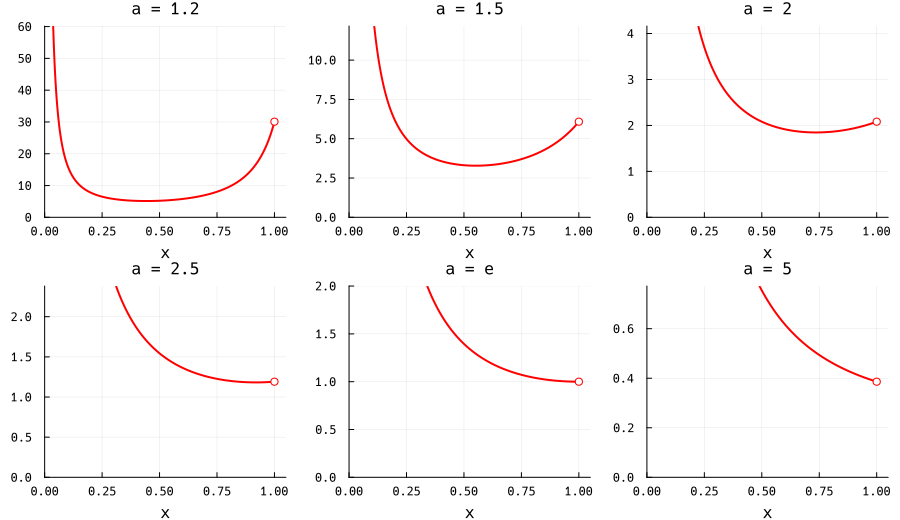

In [3]:
x = range(0.001, 0.999; length=600)

function plotf(a0, name)
    p = plot(x, f.(x, a0); lw=2, color=:red, label="", title="a = $name", titlefontsize=11,
             xlims=(0, 1.05), ylims=(0, 2 * f(1, a0)), xlabel="x")
    scatter!(p, [1], [f(1, a0)]; markercolor=:white, markerstrokecolor=:red, label="")      # 右端（含まない）
end

as = [(1.2, "1.2"), (1.5, "1.5"), (2.0, "2"), (2.5, "2.5"), (float(ℯ), "e"), (5.0, "5")]
plot([plotf(a0, name) for (a0, name) in as]...; layout=(2, 3), size=(900, 520))

## 2. $f(x)$ を微分して，$f'(x) = 0$ となる $x$ を調べる

`D` で微分し，`Factor` で積の形に整理します。

In [4]:
dfw = weval(W"Factor"(W"D"(fw, W"x")))
showtex("f'(x) = " * tex(dfw))

分母は $0 < x < 1 < a$ のとき正（$\log\dfrac{a}{x} > 0$）なので，$f'(x)$ の符号は分子の $-\left(\log\dfrac{a}{x} - 1\right)$ で決まります。

まず範囲を付けずに $f'(x) = 0$ を解きます。

In [5]:
weval(W"Solve"(W"Equal"(dfw, 0), W"x"))

W`List[List[Rule[x, Times[a, Power[E, -1]]]]]`

$x = \dfrac{a}{e}$ です。これが定義域 $0 < x < 1$ に入るかどうかを，$a > 1$ の条件と合わせて `Reduce` で調べます。

In [6]:
# 論理記号を日本語にする
jtex(s) = replace(s, "\\lor" => "\\ \\ \\text{または}\\ \\ ", "\\land" => "\\ \\text{かつ}\\ ")

cond = W`0 < x < 1 && a > 1`
r0 = weval(W"Reduce"(W"And"(W"Equal"(dfw, 0), cond), W"x", W"Reals"))
showtex("f'(x) = 0 \\iff " * jtex(tex(r0)))

$f'(x) = 0$ となる $x$ が定義域の中にあるのは $1 < a < e$ のときだけで，そのとき $x = \dfrac{a}{e}$ です。$a \geqq e$ のときは $\dfrac{a}{e} \geqq 1$ となり，定義域の外に出ます（1 節の図で $a = e$ あたりが境目に見えたことと合います）。

### $f'(x)$ の符号（増減）

$f'(x) < 0$，$f'(x) > 0$ となる範囲も同じように調べます。

In [7]:
rneg = weval(W"Reduce"(W"And"(W"Less"(dfw, 0), cond), W"x", W"Reals"))
rpos = weval(W"Reduce"(W"And"(W"Greater"(dfw, 0), cond), W"x", W"Reals"))
showtex("f'(x) < 0 \\iff " * jtex(tex(rneg)))
showtex("f'(x) > 0 \\iff " * jtex(tex(rpos)))

- $1 < a < e$ のとき：$0 < x < \dfrac{a}{e}$ で減少，$\dfrac{a}{e} < x < 1$ で増加 → $x = \dfrac{a}{e}$ で極小（最小）
- $a \geqq e$ のとき：$0 < x < 1$ でつねに減少

### 極小値

$x = \dfrac{a}{e}$ を $f(x)$ に代入します。

In [8]:
xmw = W`a/E`                                                          # 極小をとる x
mw  = weval(W"Simplify"(W"ReplaceAll"(fw, W"Rule"(W"x", xmw))))       # 極小値
showtex("f\\left(" * tex(xmw) * "\\right) = " * tex(mw))

xm = to_function(xmw, :a)      # Julia の関数：極小をとる x
m  = to_function(mw, :a);      # Julia の関数：極小値

### グラフで確かめる

1 節の図に，極小の点 $\left(\dfrac{a}{e},\ \dfrac{e^2}{a^2}\right)$ を黒丸で重ねます（$1 < a < e$ のときだけ）。

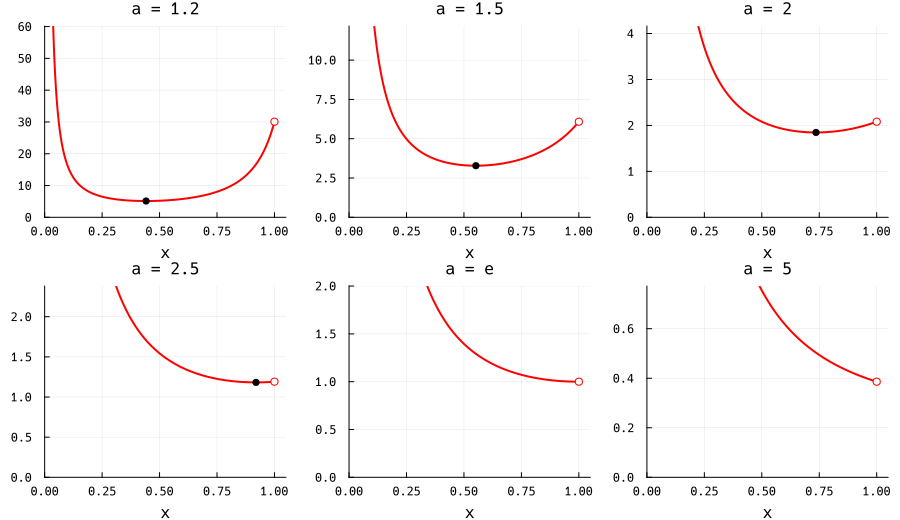

In [9]:
function plotfmin(a0, name)
    p = plotf(a0, name)
    1 < a0 < ℯ && !(a0 ≈ ℯ) && scatter!(p, [xm(a0)], [m(a0)]; color=:black, label="")      # 極小の点（a = e は浮動小数の誤差で e より小さく見えるので除く）
    p
end

plot([plotfmin(a0, name) for (a0, name) in as]...; layout=(2, 3), size=(900, 520))

## 3. $1 < a < e$ のとき：共有点が 2 個になる $(a,\ k)$

$1 < a < e$ のとき，$f(x)$ は $x = \dfrac{a}{e}$ まで減少し，そのあと増加します。共有点の個数を決めるには，極小値のほかに**両端での値（極限）**が必要です。

In [10]:
L0w = weval(W"Limit"(fw, W`x -> 0`, W`Direction -> "FromAbove"`, W`Assumptions -> a > 1`))     # x → +0
L1w = weval(W"Limit"(fw, W`x -> 1`, W`Direction -> "FromBelow"`, W`Assumptions -> a > 1`))     # x → 1-0
showtex("\\lim_{x \\to +0} f(x) = " * tex(L0w) * ",\\qquad \\lim_{x \\to 1-0} f(x) = " * tex(L1w))

top = to_function(L1w, :a);      # Julia の関数：右端の極限 1/(log a)^2

増減表は次のようになります（$1 < a < e$）。

| $x$ | $(0)$ | $\cdots$ | $\dfrac{a}{e}$ | $\cdots$ | $(1)$ |
|:-:|:-:|:-:|:-:|:-:|:-:|
| $f'(x)$ | | $-$ | $0$ | $+$ | |
| $f(x)$ | $(+\infty)$ | $\searrow$ | $\dfrac{e^2}{a^2}$ | $\nearrow$ | $\left(\dfrac{1}{(\log a)^2}\right)$ |

水平線 $y = k$ との共有点の個数は，

- $k < \dfrac{e^2}{a^2}$：0 個
- $k = \dfrac{e^2}{a^2}$：1 個（極小の点で接する）
- $\dfrac{e^2}{a^2} < k < \dfrac{1}{(\log a)^2}$：**2 個**（減少する部分と増加する部分で 1 個ずつ）
- $k \geqq \dfrac{1}{(\log a)^2}$：1 個（増加する部分は右端の値に届かないので，減少する部分だけ）

なお，$1 < a < e$ でつねに $\dfrac{e^2}{a^2} < \dfrac{1}{(\log a)^2}$ であること（2 個になる $k$ が必ずあること）を確かめておきます。

In [11]:
r = weval(W"Reduce"(W"And"(W"Less"(mw, L1w), W`1 < a < E`), W"a", W"Reals"))
showtex(tex(W"Less"(mw, L1w)) * "\\ \\text{かつ}\\ 1<a<e \\iff " * tex(r))

条件を付けても $1 < a < e$ のまま残るので，この範囲全体で成り立っています。

### 具体例で確かめる

$a = 1.5$ のとき，極小値と右端の極限の間にある $k$ では 2 個，それ以外では 1 個か 0 個です。

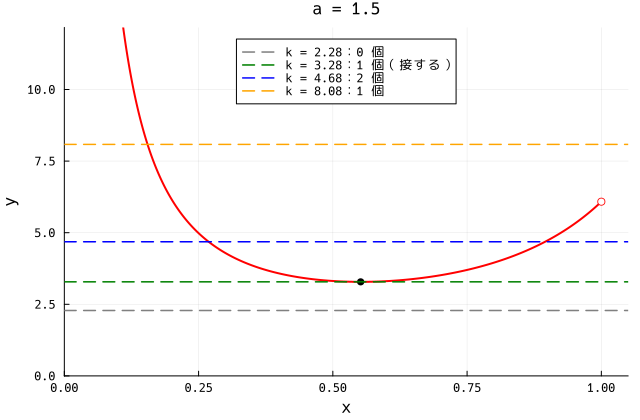

In [12]:
a0 = 1.5
p = plotfmin(a0, "1.5")
plot!(p; size=(640, 420), ylabel="y", legend=:top)
for (k0, c, lab) in [(m(a0) - 1, :gray, "0 個"), (m(a0), :green, "1 個（接する）"), ((m(a0) + top(a0)) / 2, :blue, "2 個"), (top(a0) + 2, :orange, "1 個")]
    hline!(p, [k0]; color=c, ls=:dash, lw=1.5, label="k = $(round(k0; digits=2))：$lab")
end
p

### $(a,\ k)$ を図示する

横軸を $a$，縦軸を $k$ として，$1 < a < e$ かつ $\dfrac{e^2}{a^2} < k < \dfrac{1}{(\log a)^2}$ の部分を塗ります。境界線はどちらも含みません（点線）。

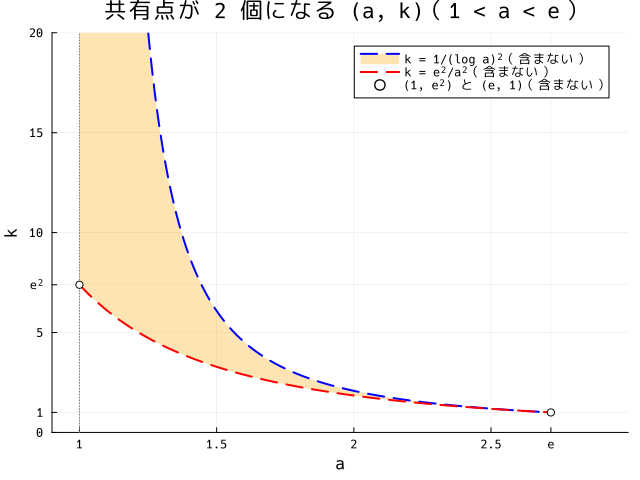

In [13]:
av = range(1.001, ℯ; length=600)

plot(av, top.(av); fillrange=m.(av), fillalpha=0.3, fillcolor=:orange, lw=2, ls=:dash, color=:blue,
     label="k = 1/(log a)²（含まない）", xlabel="a", ylabel="k", title="共有点が 2 個になる (a, k)（1 < a < e）",
     xlims=(0.9, 3), ylims=(0, 20), xticks=([1, 1.5, 2, 2.5, ℯ], ["1", "1.5", "2", "2.5", "e"]),
     yticks=([0, 1, 5, ℯ^2, 10, 15, 20], ["0", "1", "5", "e²", "10", "15", "20"]), size=(640, 480))
plot!(av, m.(av); lw=2, ls=:dash, color=:red, label="k = e²/a²（含まない）")
vline!([1]; color=:gray, ls=:dot, label="")
scatter!([1, ℯ], [ℯ^2, 1]; markercolor=:white, markerstrokecolor=:black, label="(1, e²) と (e, 1)（含まない）")

- 上の境界 $k = \dfrac{1}{(\log a)^2}$ は $a \to 1+0$ で $+\infty$ に発散します（直線 $a = 1$ が漸近線）。
- 下の境界 $k = \dfrac{e^2}{a^2}$ は $a \to 1+0$ で $e^2$ に近づきます。
- 2 つの境界は $a = e$ で出会い（点 $(e,\ 1)$），そこで領域が閉じます。

### 検算：共有点を Julia で数える

式を使わずに，$(a,\ k)$ の格子点ごとに $f(x) - k$ の符号が変わる回数（＝共有点の個数）を数えて色分けし，上の境界線を重ねます。

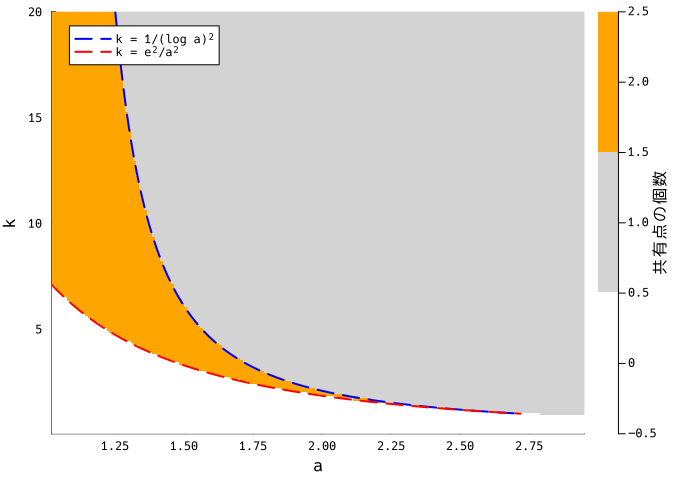

In [14]:
xg = range(1e-4, 1 - 1e-4; length=4000)
function ncross(a, k)                       # y = f(x) と y = k の共有点の個数（符号変化の回数）
    s = sign.(f.(xg, a) .- k)
    count(i -> s[i] != s[i+1], 1:length(s)-1)
end

ag = range(1.02, 2.95; length=200)
kg = range(0.05, 20; length=200)
heatmap(ag, kg, [ncross(a, k) for k in kg, a in ag]; color=cgrad([:white, :lightgray, :orange], 3; categorical=true),
        clims=(-0.5, 2.5), colorbar_title="共有点の個数", xlabel="a", ylabel="k", size=(680, 480))
plot!(av, top.(av); lw=2, ls=:dash, color=:blue, label="k = 1/(log a)²", xlims=(1.02, 2.95), ylims=(0.05, 20))
plot!(av, m.(av); lw=2, ls=:dash, color=:red, label="k = e²/a²")

数えた結果（白＝ 0 個，灰色＝ 1 個，オレンジ＝ 2 個）のうちオレンジの部分が，2 本の境界線にはさまれた部分とぴったり重なっています。$a > e$ の側（右端）には 2 個の部分がないことも見えます。